# LLM Training — Practical Lab

Hands-on companion to the lecture **The triptych of LLM Training: Pre-Training, Fine-Tuning and RLHF**.

---
## Block 0 · Setup
Runtime → Change runtime type → **T4 GPU**. Then run the cells below.

In [ ]:
!pip -q install tiktoken transformers accelerate pandas matplotlib

In [2]:
import os, json, math, torch, torch.nn as nn, torch.nn.functional as F
import pandas as pd, matplotlib.pyplot as plt
from IPython.display import HTML, display

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

CKPT_DIR = "ckpt"
os.makedirs(CKPT_DIR, exist_ok=True)

device: cpu


---
## Block 1 · Be the Language Model

A language model assigns a probability to every possible next token, given the history: **P(w | h)**.
It is the same idea as the n-gram model, but computed by a neural network over a vocabulary of ~50,000 tokens.

We use **GPT-2** (OpenAI, 2019, 124M parameters): small enough to inspect, and a **base model**,
meaning it was trained only on next-token prediction, with no chat fine-tuning.

🔮 **Predict:** what is the next word after *"The capital of Italy is"*?

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

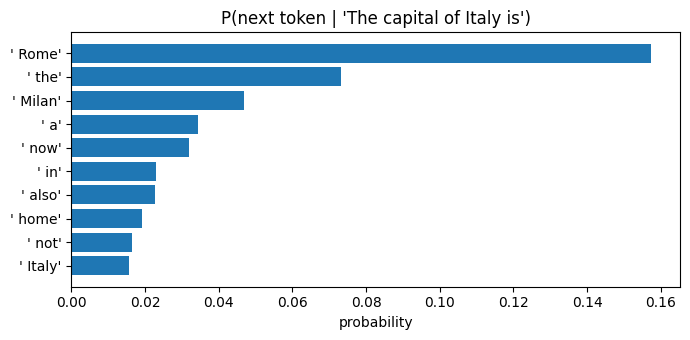

In [3]:
from transformers import AutoTokenizer, AutoModelForCausalLM

# Load GPT-2 (124M parameters, 2019): a BASE model, trained only on next-token prediction.
# The tokenizer turns text into token IDs; the model turns token IDs into next-token scores.
gpt2_tok = AutoTokenizer.from_pretrained("gpt2")
gpt2 = AutoModelForCausalLM.from_pretrained("gpt2").to(device).eval()   # eval(): inference mode, no dropout


@torch.no_grad()   # no gradients needed: we only run the model, we don't train it
def next_token_dist(prefix, k=10):
    """Return the k most likely next tokens after `prefix`, with their probabilities."""
    # 1. Text -> token IDs, shape (1, seq_len)
    ids = gpt2_tok(prefix, return_tensors="pt").input_ids.to(device)
    # 2. Forward pass -> logits, shape (1, seq_len, 50257): one raw score per vocabulary token, per position.
    #    [0, -1] keeps only the last position = the prediction for the NEXT token.
    # 3. softmax turns raw scores into probabilities that sum to 1 -> this is P(w | h)
    probs = gpt2(ids).logits[0, -1].softmax(-1)
    # 4. Keep the k most likely tokens
    top = probs.topk(k)
    # 5. IDs -> readable strings. repr() makes leading spaces visible: ' Rome' vs 'Rome'
    return [(repr(gpt2_tok.decode(i)), p.item()) for p, i in zip(top.values, top.indices)]


def plot_next_token(prefix, k=10):
    """Horizontal bar chart of the top-k next-token probabilities."""
    dist = next_token_dist(prefix, k)[::-1]          # reverse so the most likely token is on top
    plt.figure(figsize=(7, 3.5))
    plt.barh([t for t, _ in dist], [p for _, p in dist])
    plt.xlabel("probability"); plt.title(f"P(next token | {prefix!r})")
    plt.tight_layout(); plt.show()


# The model does not "know" the answer: it gives a probability to every possible next token.
plot_next_token("The capital of Italy is")

### Context changes the prediction

The word *"bank"* is ambiguous. Does the model know which bank we mean?
Each panel also shows an **uncertainty meter**: roughly how many equally likely words the model is choosing between.

🔮 **Predict:** which of the three prefixes will be the most certain?

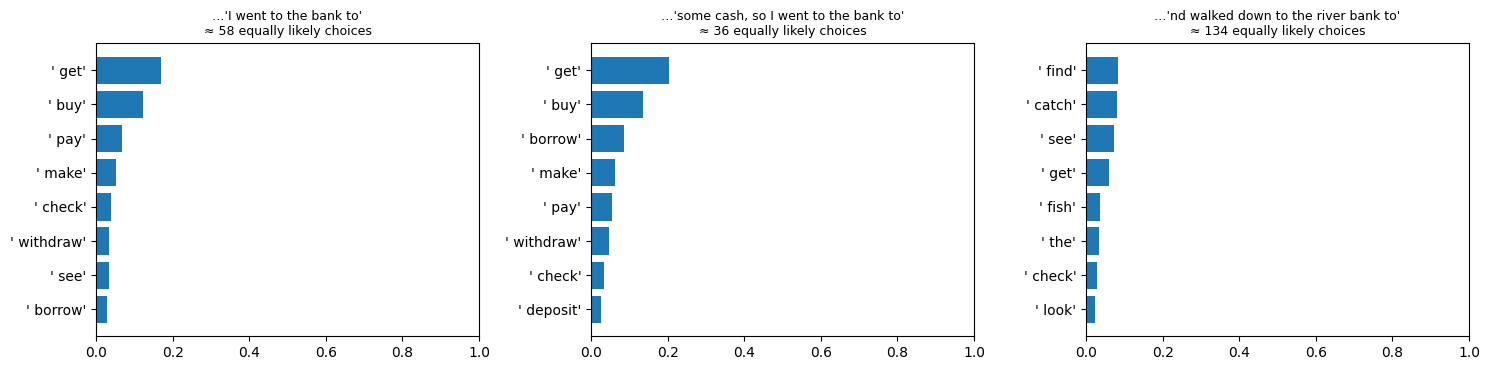

In [4]:
@torch.no_grad()
def entropy_bits(prefix):
    """Uncertainty of the next-token distribution, in bits (Shannon entropy)."""
    ids = gpt2_tok(prefix, return_tensors="pt").input_ids.to(device)
    probs = gpt2(ids).logits[0, -1].softmax(-1)
    return -(probs * probs.clamp_min(1e-12).log2()).sum().item()

def compare_prefixes(prefixes, k=8):
    """Side-by-side next-token distributions for several prefixes."""
    fig, axes = plt.subplots(1, len(prefixes), figsize=(5 * len(prefixes), 3.8))
    for ax, prefix in zip(axes, prefixes):
        dist = next_token_dist(prefix, k)[::-1]
        ax.barh([t for t, _ in dist], [p for _, p in dist])
        # 2**entropy = "effective number of choices": 1 = certain, 1000 = no idea
        ax.set_title(f"…{prefix[-35:]!r}\n≈ {2 ** entropy_bits(prefix):.0f} equally likely choices", fontsize=9)
        ax.set_xlim(0, 1)
    plt.tight_layout(); plt.show()

# Same word "bank": the context before it decides the meaning, and the prediction
compare_prefixes([
    "I went to the bank to",
    "I needed some cash, so I went to the bank to",
    "We took our fishing rods and walked down to the river bank to",
])

### 🌡️ What is temperature?

The model's last layer outputs **logits**: one raw score per token in the vocabulary.
Softmax turns them into probabilities. **Temperature T** divides the logits *before* the softmax:

$$P(w_i) = \frac{e^{z_i / T}}{\sum_j e^{z_j / T}}$$

The model is **not** changed. Only the way we **pick** from its distribution changes.

**Example:** 3 candidate next tokens after *"Once upon a time, there was a"*

| Token | Logit | T = 0.5 | T = 1 | T = 2 |
|---|---|---|---|---|
| " dog" | 2.0 | **0.87** | 0.67 | 0.51 |
| " cat" | 1.0 | 0.12 | 0.24 | 0.31 |
| " dragon" | 0.0 | 0.02 | 0.09 | 0.19 |

- **T < 1 sharpens** the distribution: the favorite gets even more likely → safe, repetitive text
- **T = 1** uses the model's original probabilities
- **T > 1 flattens** it: unlikely tokens get a real chance → creative, then chaotic
- **T → 0** always picks the top token (**greedy decoding**); **T → ∞** picks uniformly at random

In practice, chat models typically use T ≈ 0.7–1.0, often combined with **top-k** (sample only from the k best tokens) or **top-p** (from the smallest set of tokens whose probabilities add up to p).

In [5]:
@torch.no_grad()
def generate_colored(prefix, n_tokens=30, temperature=1.0, seed=0):
    """Generate text; color each token by the probability the model gave it (at T=1)."""
    torch.manual_seed(seed)
    ids = gpt2_tok(prefix, return_tensors="pt").input_ids.to(device)
    html = f"<b>T={temperature}</b> &nbsp; <span style='color:#888'>{prefix}</span>"
    for _ in range(n_tokens):
        logits = gpt2(ids).logits[0, -1]
        if temperature == 0:
            nxt = logits.argmax()                                          # greedy
        else:
            nxt = torch.multinomial((logits / temperature).softmax(-1), 1)[0]  # sample
        p = logits.softmax(-1)[nxt].item()            # how likely the model REALLY thought it was
        color = "#bbf7d0" if p > 0.5 else "#fde68a" if p > 0.1 else "#fecaca"
        tok = gpt2_tok.decode(nxt).replace("<", "&lt;").replace("\n", "↵ ")
        html += f"<span title='p = {p:.3f}' style='background:{color};color:#000;white-space:pre'>{tok}</span>"
        ids = torch.cat([ids, nxt.view(1, 1)], dim=1)
    display(HTML(html + "<br><br>"))

display(HTML("🟩 p > 0.5 &nbsp; 🟨 0.1–0.5 &nbsp; 🟥 p < 0.1 &nbsp; (hover a token for its probability)"))
prefix = "Once upon a time, there was a"
for T in [0, 0.7, 1.5]:
    generate_colored(prefix, temperature=T)

### Generation = repeat "predict next token" in a loop
- **greedy** (temperature 0): always pick the most likely token
- **sampling** with temperature T: divide the logits by T, then sample. Low T → safe, high T → creative/chaotic

In [6]:
@torch.no_grad()
def generate(prefix, n_tokens=20, temperature=0.0, seed=0):
    torch.manual_seed(seed)
    ids = gpt2_tok(prefix, return_tensors="pt").input_ids.to(device)
    for _ in range(n_tokens):
        logits = gpt2(ids).logits[0, -1]
        if temperature == 0:
            nxt = logits.argmax()
        else:
            nxt = torch.multinomial((logits / temperature).softmax(-1), 1)[0]
        ids = torch.cat([ids, nxt.view(1, 1)], dim=1)
    return gpt2_tok.decode(ids[0])

prefix = "Once upon a time"
for T in [0.0, 0.7, 1.5]:
    print(f"--- T={T} ---\n{generate(prefix, 30, T)}\n")

--- T=0.0 ---
Once upon a time, the world was a place of great beauty and great danger. The world was a place of great danger, and the world was a place of great

--- T=0.7 ---
Once upon a time, when the world was plunged into darkness, the sun had the energy to shine forth and shine out, and yet the sun remained canny and dull

--- T=1.5 ---
Once upon a time along this pilot journeyave Girls... is "tree legs bipartisan the spill that shameful swell CathP wrestler roars forthPlus Chin decreases she soBO82



**Takeaway:** an LLM produces text **one token at a time**, sampled from a probability distribution.
It never goes back to edit: once an unlikely token is picked, it must continue from it.

---
## Block 2 · Tokenization

Models don't see characters or words: they see **tokens** (integer IDs).

🔮 **Predict:** the same sentence in English, Italian and Macedonian — which costs the most tokens?

In [ ]:
import tiktoken

TEXTS = {
    "Simple":       "7 + 5 =",
    "Intermediate": "24 * 13 - 17 =",
    "Advanced":     "(125 + 37) * 8 / 4 - 19 =",
    "Complex":      "((234 * 17) - 156) / 6 + 2**5 =",
}

# Each tokenizer -> (encode, decode_one_token)
TOKENIZERS = {}
for name, enc_name in [("GPT-2", "gpt2"), ("GPT-4o", "o200k_base")]:
    enc = tiktoken.get_encoding(enc_name)
    TOKENIZERS[name] = (enc.encode, lambda i, enc=enc: enc.decode([i]))
for name, repo in [("Qwen2.5", "Qwen/Qwen2.5-0.5B"), ("Llama 3", "unsloth/Llama-3.2-1B")]:
    try:
        t = AutoTokenizer.from_pretrained(repo)
        TOKENIZERS[name] = (lambda s, t=t: t.encode(s, add_special_tokens=False), lambda i, t=t: t.decode([i]))
    except Exception as e:
        print(f"skipping {name}: {e}")

COLORS = ["#fde68a", "#bbf7d0", "#bfdbfe", "#fbcfe8", "#ddd6fe", "#fed7aa"]
def show_tokens(text, tokenizer="GPT-2"):
    encode, decode_one = TOKENIZERS[tokenizer]
    ids = encode(text)
    spans = "".join(
        f'<span style="background:{COLORS[k % len(COLORS)]};color:#000;padding:2px 1px;margin:1px;'
        f'border-radius:3px;white-space:pre">{decode_one(i).replace("<", "&lt;")}</span>'
        for k, i in enumerate(ids))
    display(HTML(f"<b>{tokenizer}</b> · {len(ids)} tokens<br><div style='font-family:monospace;font-size:15px;line-height:2'>{spans}</div>"))

for label, text in TEXTS.items():
    print(label); show_tokens(text, "GPT-2")

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

English


Italian


Macedonian


Numbers


Code


In [8]:
# Token counts: same text, different tokenizers
counts = pd.DataFrame({tok: {label: len(TOKENIZERS[tok][0](text)) for label, text in TEXTS.items()}
                       for tok in TOKENIZERS})
counts

,GPT-2,GPT-4o,Qwen2.5,Llama 3
English,7,7,7,7
Italian,14,13,15,15
Macedonian,51,14,20,19
Numbers,8,9,17,9
Code,15,11,11,11


Non-English text, especially in non-Latin scripts, often costs more tokens → more expensive API calls and a shorter effective context window. Newer tokenizers (bigger vocabularies) narrow the gap.

### 💶 Tokens are money

LLM APIs bill **per token**, with two separate prices:
- **Input tokens**: everything you send (system prompt, chat history, documents, your question)
- **Output tokens**: everything the model generates. These are usually **3–5× more expensive**

Why is output more expensive? Remember Block 1: the **input** is processed in *one* parallel forward pass,
while the **output** is generated *one token at a time*, one forward pass per token.

So the token counts we just saw translate directly into money.

In [9]:
# Illustrative prices in $ per 1M tokens. Check the provider's pricing page for real numbers.
PRICE_IN, PRICE_OUT = 1.00, 4.00

# The same customer-support system prompt in three languages
PROMPTS = {
    "English":    "Our customer support assistant answers questions about orders, deliveries and refunds. "
                  "Please describe your problem in detail, and include your order number if you have one.",
    "Italian":    "Il nostro assistente clienti risponde a domande su ordini, consegne e rimborsi. "
                  "Descrivi il tuo problema nel dettaglio e includi il numero d'ordine, se ne hai uno.",
    "Macedonian": "Нашиот асистент за поддршка на корисници одговара на прашања за нарачки, испораки и "
                  "враќање на пари. Опишете го вашиот проблем детално и вклучете го бројот на нарачката ако го имате.",
}
REQUESTS = 1_000_000   # a chatbot with 1M conversations: the system prompt is sent every time

rows = []
for lang, text in PROMPTS.items():
    n_old = len(TOKENIZERS["GPT-2"][0](text))     # old tokenizer (2019, 50k vocab)
    n_new = len(TOKENIZERS["GPT-4o"][0](text))    # newer tokenizer (2024, 200k vocab)
    rows.append((lang, n_old, n_new, n_new * REQUESTS / 1e6 * PRICE_IN))

df = pd.DataFrame(rows, columns=["language", "tokens (GPT-2)", "tokens (GPT-4o)", "cost for 1M requests ($)"])
df["vs English"] = (df["tokens (GPT-4o)"] / df["tokens (GPT-4o)"].iloc[0]).map("{:.1f}×".format)
df

,language,tokens (GPT-2),tokens (GPT-4o),cost for 1M requests ($),vs English
0,English,30,30,30.0,1.0×
1,Italian,57,44,44.0,1.5×
2,Macedonian,199,64,64.0,2.1×


### Why can't LLMs count the r's in "strawberry"?

In [10]:
for tok in TOKENIZERS:
    show_tokens("strawberry", tok)

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


### 🧮 Experiment: can GPT-2 do addition?

We show GPT-2 a few solved examples (few-shot prompting), then ask a new sum.
We test 30 random problems for each size: 1-digit, 2-digit, … 5-digit numbers.

🔮 **Predict:** at how many digits will GPT-2 drop below 50% accuracy?

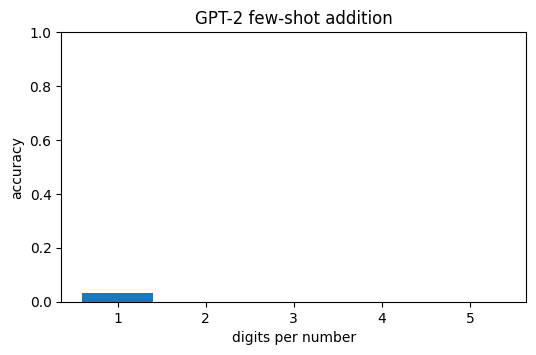

In [12]:
import random

# A few solved examples so the model understands the format
FEW_SHOT = "12 + 35 = 47\n58 + 21 = 79\n7 + 6 = 13\n140 + 23 = 163\n"

@torch.no_grad()
def ask_gpt2(a, b):
    """Ask GPT-2 to complete 'a + b =' (greedy decoding), return its answer as a string."""
    prompt = FEW_SHOT + f"{a} + {b} ="
    ids = gpt2_tok(prompt, return_tensors="pt").input_ids.to(device)
    out = gpt2.generate(ids, max_new_tokens=10, do_sample=False, pad_token_id=gpt2_tok.eos_token_id)
    return gpt2_tok.decode(out[0, ids.shape[1]:]).split("\n")[0].strip()   # keep the first line only

random.seed(0)
results = []
for n_digits in range(1, 6):
    lo, hi = (0 if n_digits == 1 else 10 ** (n_digits - 1)), 10 ** n_digits - 1
    for _ in range(30):
        a, b = random.randint(lo, hi), random.randint(lo, hi)
        answer = ask_gpt2(a, b)
        results.append(dict(digits=n_digits, problem=f"{a} + {b}", correct=str(a + b),
                            gpt2=answer, ok=answer == str(a + b)))
res = pd.DataFrame(results)

acc = res.groupby("digits")["ok"].mean()
plt.figure(figsize=(6, 3.5))
plt.bar(acc.index, acc.values)
plt.xlabel("digits per number"); plt.ylabel("accuracy"); plt.ylim(0, 1)
plt.title("GPT-2 few-shot addition"); plt.show()

In [ ]:
# The answers look plausible: right format, roughly the right size, but wrong digits
res[~res.ok].sample(8, random_state=0)

In [ ]:
def digit_check(row):
    c, g = row.correct, row.gpt2
    return pd.Series({"right length": len(g) == len(c),
                      "first digit right": g[:1] == c[:1],
                      "last digit right": g[-1:] == c[-1:]})

# Problems with 3+ digits: which parts of the answer does GPT-2 get right?
res[res.digits >= 3].apply(digit_check, axis=1).mean().to_frame("share of answers")

**Why LLMs struggle with arithmetic**

1. **Tokens hide the digits.** `4721` may be one token, `47`+`21`, or `472`+`1`, so the digit columns never line up.
2. **The model writes left to right, but carries go right to left.** To write the *first* digit of the answer,
   the model must already know every carry from the digits on the right, and it has to compute all of that
   **in a single forward pass**, with a fixed amount of computation per token.
3. **It learned patterns, not an algorithm.** `2 + 2 = 4` appears millions of times on the web, so it's memorized.
   `4721 + 3856` probably never appears, so the model guesses something that *looks* right.

**How modern LLMs cope:** better tokenizers (digit-by-digit), **writing out intermediate steps** (more tokens = more
computation, "models need tokens to think"), and **tools** (calling a calculator or Python).

✏️ **Try at home:** remove the few-shot examples. Does accuracy change? Try subtraction and multiplication.

---
## Block 3 · Pre-training

Pre-training = **next-token prediction** on a huge corpus. Here a *tiny* GPT (~0.8M parameters, character-level)
was trained on TinyShakespeare (1 MB of text) — see the Appendix.

Model definition (same architecture family as GPT-2, just much smaller):

In [ ]:
class Block(nn.Module):
    def __init__(self, n_embd, n_head):
        super().__init__()
        self.n_head = n_head
        self.ln1, self.ln2 = nn.LayerNorm(n_embd), nn.LayerNorm(n_embd)
        self.qkv = nn.Linear(n_embd, 3 * n_embd)
        self.proj = nn.Linear(n_embd, n_embd)
        self.mlp = nn.Sequential(nn.Linear(n_embd, 4 * n_embd), nn.GELU(), nn.Linear(4 * n_embd, n_embd))

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(self.ln1(x)).split(C, dim=2)
        q, k, v = (t.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) for t in (q, k, v))
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)   # masked self-attention
        x = x + self.proj(y.transpose(1, 2).reshape(B, T, C))
        return x + self.mlp(self.ln2(x))

class TinyGPT(nn.Module):
    def __init__(self, vocab_size, block_size, n_layer, n_head, n_embd):
        super().__init__()
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab_size, n_embd)
        self.pos_emb = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        T = idx.shape[1]
        x = self.tok_emb(idx) + self.pos_emb(torch.arange(T, device=idx.device))
        logits = self.head(self.ln_f(self.blocks(x)))
        loss = None if targets is None else F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, n_new, temperature=0.8):
        for _ in range(n_new):
            logits, _ = self(idx[:, -self.block_size:])
            probs = (logits[:, -1] / temperature).softmax(-1)
            idx = torch.cat([idx, torch.multinomial(probs, 1)], dim=1)
        return idx

def load_tiny(step):
    ck = torch.load(f"{CKPT_DIR}/step_{step}.pt", map_location=device)
    model = TinyGPT(**ck["cfg"]).to(device).eval()
    model.load_state_dict(ck["state"])
    return model, ck["chars"]

### 📉 What does the loss measure?

At every position the model outputs a probability for **every** token. The **cross-entropy loss** looks at
only one of them: the probability given to the token that **actually comes next** in the text.

$$\mathcal{L} = -\log P_\theta(\text{correct next token} \mid \text{context})$$

The loss of a text is the **average over all positions**.

| P(correct token) | Loss |
|---|---|
| 1.0 (certain and right) | 0.00 |
| 0.5 | 0.69 |
| 0.1 | 2.30 |
| 1/65 (random guess among 65 characters) | 4.17 |
| 0.01 | 4.61 |

Training = changing the weights so that this number goes **down** on trillions of tokens.

In [14]:
vocab = ["Rome", "Paris", "Milan", "the", "pizza"]

# 1. The model's raw output at ONE position: one score (logit) per vocabulary token
logits = torch.tensor([3.0, 1.0, 0.5, 2.0, -1.0])

# 2. Softmax turns scores into probabilities (positive, sum to 1)
probs = logits.softmax(-1)
for w, p in zip(vocab, probs):
    print(f"{w:>6}: {p:.4f}")
print(f"   sum: {probs.sum():.4f}\n")

# 3. The correct next token is "Rome" (index 0). Loss = -log P(correct token)
target = 0
print(f"correct = Rome  -> P = {probs[target]:.4f} -> loss = {-torch.log(probs[target]):.4f}")
print(f"F.cross_entropy gives the same: {F.cross_entropy(logits.unsqueeze(0), torch.tensor([target])):.4f}\n")

# 4. Same prediction, but suppose the correct token was "pizza"
print(f"correct = pizza -> P = {probs[4]:.4f} -> loss = {-torch.log(probs[4]):.4f}")

  Rome: 0.6236
 Paris: 0.0844
 Milan: 0.0512
   the: 0.2294
 pizza: 0.0114
   sum: 1.0000

correct = Rome  -> P = 0.6236 -> loss = 0.4723
F.cross_entropy gives the same: 0.4723

correct = pizza -> P = 0.0114 -> loss = 4.4723


In [15]:
# A text = many positions. Logits: (positions, vocab). Targets: one correct token per position.
logits = torch.tensor([[3.0, 1.0, 0.5, 2.0, -1.0],   # position 1: fairly sure "Rome"
                       [0.2, 0.1, 0.3, 4.0,  0.0],   # position 2: very sure "the"
                       [0.0, 0.0, 0.0, 0.0,  0.0]])  # position 3: no idea (all equal)
targets = torch.tensor([0, 3, 4])                    # correct tokens: Rome, the, pizza

per_position = -logits.log_softmax(-1)[torch.arange(3), targets]   # -log P(correct) at each position
print("loss per position:", per_position.round(decimals=3).tolist())
print(f"mean            : {per_position.mean():.4f}")
print(f"F.cross_entropy : {F.cross_entropy(logits, targets):.4f}")

loss per position: [0.47200000286102295, 0.0820000022649765, 1.6089999675750732]
mean            : 0.7213
F.cross_entropy : 0.7213


In [16]:
# Ask PyTorch: how should each logit change to reduce the loss?
logits = torch.tensor([3.0, 1.0, 0.5, 2.0, -1.0], requires_grad=True)
loss = F.cross_entropy(logits.unsqueeze(0), torch.tensor([0]))   # correct token: Rome
loss.backward()

print("gradient of the loss w.r.t. each logit:")
for w, g in zip(vocab, logits.grad):
    print(f"{w:>6}: {g:+.4f}")

# Gradient descent: move AGAINST the gradient
with torch.no_grad():
    new_logits = logits - 1.0 * logits.grad          # learning rate = 1.0
print(f"\nP(Rome) before: {logits.softmax(-1)[0]:.4f}   after one step: {new_logits.softmax(-1)[0]:.4f}")
print(f"loss    before: {loss.item():.4f}   after one step: {F.cross_entropy(new_logits.unsqueeze(0), torch.tensor([0])):.4f}")

gradient of the loss w.r.t. each logit:
  Rome: -0.3764
 Paris: +0.0844
 Milan: +0.0512
   the: +0.2294
 pizza: +0.0114

P(Rome) before: 0.6236   after one step: 0.7396
loss    before: 0.4723   after one step: 0.3016


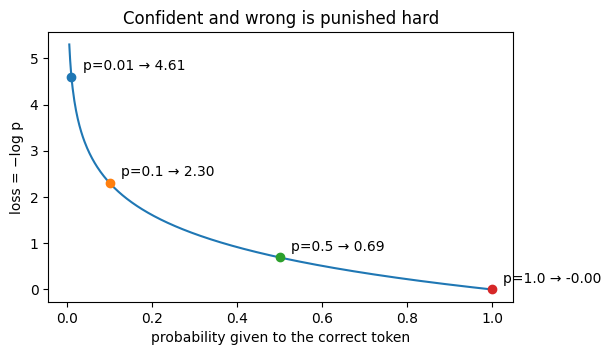

In [13]:
p = torch.linspace(0.005, 1, 500)
plt.figure(figsize=(6, 3.5))
plt.plot(p, -torch.log(p))
for pt in [0.01, 0.1, 0.5, 1.0]:
    plt.scatter(pt, -math.log(pt), zorder=3)
    plt.annotate(f"p={pt} → {-math.log(pt):.2f}", (pt, -math.log(pt)), xytext=(8, 5), textcoords="offset points")
plt.xlabel("probability given to the correct token"); plt.ylabel("loss = −log p")
plt.title("Confident and wrong is punished hard"); plt.show()

### The loss curve
Cross-entropy of the next character. Random guessing over 65 characters ≈ ln(65) ≈ 4.17.

In [17]:
losses = json.load(open(f"{CKPT_DIR}/losses.json"))
steps, vals = zip(*losses)
plt.figure(figsize=(7, 3.5))
plt.plot(steps, vals)
plt.axhline(math.log(65), ls="--", c="gray", label="random guess")
plt.xlabel("training step"); plt.ylabel("loss"); plt.legend(); plt.title("Tiny GPT on TinyShakespeare")
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'ckpt/losses.json'

🔮 **Predict:** what does the model write at **step 0**, before any training?

In [ ]:
for step in [0, 200, 1000, 5000]:
    model, chars = load_tiny(step)
    torch.manual_seed(0)
    start = torch.tensor([[chars.index("\n")]], device=device)
    out = model.generate(start, 250)[0].tolist()
    print(f"=============== step {step} ===============")
    print("".join(chars[i] for i in out))

### ✂️ How much does real pre-training cost?
Rule of thumb: training FLOPs ≈ **6 · N · D** (N = parameters, D = training tokens).

In [ ]:
def pretrain_cost(N, D, gpu_flops=312e12, utilization=0.40, usd_per_gpu_hour=30 / 8):
    flops = 6 * N * D
    gpu_hours = flops / (gpu_flops * utilization) / 3600
    return flops, gpu_hours, gpu_hours * usd_per_gpu_hour

flops, hours, usd = pretrain_cost(N=7e9, D=2e12)      # Llama 2 7B: 2T tokens, A100 GPUs
print(f"FLOPs     : {flops:.1e}")
print(f"GPU-hours : {hours:,.0f}   (Meta reported 184,320 A100 GPU-hours)")
print(f"Cost      : ${usd:,.0f}   (at $30/h for an 8xA100 node)")

✏️ **Try at home:** Llama 3 70B was trained on ~15T tokens. Estimate its cost. How many days on 1,000 GPUs?

**Takeaway:** pre-training is just next-token prediction, at enormous scale. The result is a **base model**: an "internet document simulator", not an assistant.

---
## Block 4 · SFT, Chat Templates, Hallucinations

Compare a **base** model with its **instruction-tuned** (SFT) version: [SmolLM2-135M](https://huggingface.co/HuggingFaceTB/SmolLM2-135M) vs SmolLM2-135M-Instruct.

🔮 **Predict:** what does the *base* model do with *"How do I cook pasta?"*

In [18]:
tok_sm = AutoTokenizer.from_pretrained("HuggingFaceTB/SmolLM2-135M-Instruct")
base = AutoModelForCausalLM.from_pretrained("HuggingFaceTB/SmolLM2-135M").to(device).eval()
inst = AutoModelForCausalLM.from_pretrained("HuggingFaceTB/SmolLM2-135M-Instruct").to(device).eval()

@torch.no_grad()
def complete(model, text, max_new_tokens=80):
    ids = tok_sm(text, return_tensors="pt").input_ids.to(device)
    out = model.generate(ids, max_new_tokens=max_new_tokens, do_sample=False,
                         repetition_penalty=1.2, pad_token_id=tok_sm.eos_token_id)
    return tok_sm.decode(out[0, ids.shape[1]:], skip_special_tokens=False)

def chat_prompt(user_msg, system=None):
    msgs = ([{"role": "system", "content": system}] if system else []) + [{"role": "user", "content": user_msg}]
    return tok_sm.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

q = "How do I cook pasta?"
print("=== BASE, raw text ===\n", complete(base, q))
print("\n=== INSTRUCT, with chat template ===\n", complete(inst, chat_prompt(q)))

config.json:   0%|          | 0.00/861 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.76k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  269MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

=== BASE, raw text ===
 
A. You can use a regular pot, but you will need to add water and salt first before adding the sauce (or other ingredients).
B. You could also try using an electric range or stovetop instead of a gas one!
C. Both options work great for making delicious homemade sauces like this one – just remember that some recipes call for specific amounts of oil based on

=== INSTRUCT, with chat template ===
 Cooking pasta can be done in various ways. Here's how to make it:

1. **Baking**: Preheat your oven or pan and bake the pasta according to its size (usually 8-inch). You may need to add some oil for cooking if you're using nonstick pans. Once cooked, let it cool before slicing into thin strips.

2. **Roasting


### What the model actually sees: the chat template
The conversation is flattened into **one string with special tokens** (ChatML), same as on the whiteboard.

In [19]:
print(chat_prompt("How do I cook pasta?", system="You are a helpful assistant."))

<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
How do I cook pasta?<|im_end|>
<|im_start|>assistant



🔮 **Predict:** if we give the *base* model the chat template, does it become an assistant?

In [20]:
print("=== BASE, with chat template ===\n", complete(base, chat_prompt(q)))
print("\n=== INSTRUCT, without chat template ===\n", complete(inst, q))

=== BASE, with chat template ===
 I have an email address and it's not working. How can i get my message to work again?<|endoftext|>

=== INSTRUCT, without chat template ===
 <|im_end|>


The format alone is not enough: the **behavior** comes from fine-tuning on conversations in that format. And the fine-tuned model works best only *inside* the format it was trained on.

### 💬 Chat templates: how a conversation becomes text

An LLM only reads **one long string of tokens**. A chat (a list of messages with roles) must be flattened
into that string. The **chat template** does it, using **special tokens** that mark who is speaking.

Every model family was fine-tuned with its **own** format, so each one needs its own template.
The template ships with the tokenizer (in `tokenizer_config.json`), and `apply_chat_template` applies it.

🔮 **Predict:** will five different models format the same conversation the same way?

In [21]:
# Tokenizers only (no model weights): fast to download.
# unsloth/* are ungated mirrors of the official Llama, Mistral and Gemma repos.
TEMPLATE_MODELS = {
    "SmolLM2 (ChatML)": "HuggingFaceTB/SmolLM2-135M-Instruct",
    "Qwen2.5":          "Qwen/Qwen2.5-0.5B-Instruct",
    "Llama 3.2":        "unsloth/Llama-3.2-1B-Instruct",
    "Mistral v0.3":     "unsloth/mistral-7b-instruct-v0.3",
    "Gemma 2":          "unsloth/gemma-2-2b-it",
}
chat_toks = {}
for name, repo in TEMPLATE_MODELS.items():
    try:
        chat_toks[name] = AutoTokenizer.from_pretrained(repo)
    except Exception as e:
        print(f"skipping {name}: {e}")

conversation = [
    {"role": "system",    "content": "You are a helpful cooking assistant."},
    {"role": "user",      "content": "How do I cook pasta?"},
    {"role": "assistant", "content": "Boil salted water, add the pasta, cook 8-12 minutes."},
    {"role": "user",      "content": "How do I know when it's done?"},
]

for name, tok in chat_toks.items():
    print(f"{'=' * 25} {name} {'=' * 25}")
    try:
        print(tok.apply_chat_template(conversation, tokenize=False, add_generation_prompt=True))
    except Exception as e:
        print(f"❌ ERROR: {e}")      # some templates reject some roles
    print()

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/47.0k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.5MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

========================= SmolLM2 (ChatML) =========================
<|im_start|>system
You are a helpful cooking assistant.<|im_end|>
<|im_start|>user
How do I cook pasta?<|im_end|>
<|im_start|>assistant
Boil salted water, add the pasta, cook 8-12 minutes.<|im_end|>
<|im_start|>user
How do I know when it's done?<|im_end|>
<|im_start|>assistant


========================= Qwen2.5 =========================
<|im_start|>system
You are a helpful cooking assistant.<|im_end|>
<|im_start|>user
How do I cook pasta?<|im_end|>
<|im_start|>assistant
Boil salted water, add the pasta, cook 8-12 minutes.<|im_end|>
<|im_start|>user
How do I know when it's done?<|im_end|>
<|im_start|>assistant


========================= Llama 3.2 =========================
<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 23 Oct 2026

You are a helpful cooking assistant.<|eot_id|><|start_header_id|>user<|end_header_id|>

How do I cook pasta?<|eot_id|><|start

### 🛠️ Tool use in the template

A tool call is a conversation with two extra steps:
1. The **assistant** answers with a structured *tool call* instead of text
2. **Our code** runs the function, and the result goes back as a message with role `tool`

The template turns all of this, including the tool descriptions, into plain text.

In [30]:
def get_weather(city: str) -> str:
    """
    Get the current weather in a city.

    Args:
        city: The name of the city
    """
    return "22°C, sunny"

tool_conversation = [
    {"role": "user", "content": "What's the weather in Rome?"},
    {"role": "assistant", "content": "", "tool_calls": [
        {"type": "function", "function": {"name": "get_weather", "arguments": {"city": "Rome"}}}]},
    {"role": "tool", "name": "get_weather", "content": "22°C, sunny"},
    {"role": "assistant", "content": "It's 22°C and sunny in Rome."},
]

for name in ["Qwen2.5", "Llama 3.2"]:
    if name in chat_toks:
        print(f"{'=' * 25} {name} {'=' * 25}")
        print(chat_toks[name].apply_chat_template(tool_conversation, tools=[get_weather], tokenize=False))

========================= Qwen2.5 =========================
<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"type": "function", "function": {"name": "get_weather", "description": "Get the current weather in a city.", "parameters": {"type": "object", "properties": {"city": {"type": "string", "description": "The name of the city"}}, "required": ["city"]}, "return": {"type": "string"}}}
</tools>

For each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:
<tool_call>
{"name": <function-name>, "arguments": <args-json-object>}
</tool_call><|im_end|>
<|im_start|>user
What's the weather in Rome?<|im_end|>
<|im_start|>assistant
<tool_call>
{"name": "get_weather", "arguments": {"city": "Rome"}}
</tool_call><|im_end|>
<|im_start|>user
<tool

### 🖼️ Multimodal templates

Images and audio enter the conversation as **placeholder tokens** in the template.
The processor then replaces each placeholder with many tokens, filled with vectors from a vision (or audio) encoder.
To the language model, an image is just **more tokens**.

In [22]:
from transformers import AutoProcessor
from PIL import Image

vl_proc = AutoProcessor.from_pretrained("Qwen/Qwen2.5-VL-3B-Instruct")   # processor only, no weights

mm_messages = [{"role": "user", "content": [
    {"type": "image"},
    {"type": "text", "text": "What is in this picture?"},
]}]
mm_text = vl_proc.apply_chat_template(mm_messages, tokenize=False, add_generation_prompt=True)
print(mm_text)

preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
<|vision_start|><|image_pad|><|vision_end|>What is in this picture?<|im_end|>
<|im_start|>assistant



### 🧩 Under the hood: a chat template is a Jinja program

Jinja is a text-templating language (the one used by web frameworks like Flask):
- `{{ x }}` prints a value
- `{% for … %} … {% endfor %}` and `{% if … %} … {% endif %}` add logic

The template receives the variables `messages`, `add_generation_prompt`, `tools`…, and outputs **one string**.
Let's write our own.

In [24]:
from jinja2 import Template

MY_TEMPLATE = """{% for m in messages %}<|{{ m.role }}|>
{{ m.content }}<|end|>
{% endfor %}{% if add_generation_prompt %}<|assistant|>
{% endif %}"""

# Pure Jinja, no transformers involved: it's only text generation
print(Template(MY_TEMPLATE).render(messages=conversation, add_generation_prompt=True))

<|system|>
You are a helpful cooking assistant.<|end|>
<|user|>
How do I cook pasta?<|end|>
<|assistant|>
Boil salted water, add the pasta, cook 8-12 minutes.<|end|>
<|user|>
How do I know when it's done?<|end|>
<|assistant|>



In [25]:
CHATML = """{% for m in messages %}<|im_start|>{{ m.role }}
{{ m.content }}<|im_end|>
{% endfor %}{% if add_generation_prompt %}<|im_start|>assistant
{% endif %}"""

real_tok = chat_toks["SmolLM2 (ChatML)"]
mine = Template(CHATML).render(messages=conversation, add_generation_prompt=True)
real = real_tok.apply_chat_template(conversation, tokenize=False, add_generation_prompt=True)
print("identical to SmolLM2's template:", mine == real)

identical to SmolLM2's template: True


In [26]:
CHATML_DEFAULT = ("{% if messages[0].role != 'system' %}<|im_start|>system\n"
                  "You are a helpful AI assistant named SmolLM, trained by Hugging Face<|im_end|>\n{% endif %}") + CHATML

no_sys = conversation[1:]
print(Template(CHATML_DEFAULT).render(messages=no_sys, add_generation_prompt=True) ==
      real_tok.apply_chat_template(no_sys, tokenize=False, add_generation_prompt=True))

True


In [27]:
# A template is just a string attribute of the tokenizer: we can replace it
my_tok = AutoTokenizer.from_pretrained("HuggingFaceTB/SmolLM2-135M-Instruct")
my_tok.chat_template = MY_TEMPLATE
print(my_tok.apply_chat_template(conversation, tokenize=False, add_generation_prompt=True))

<|system|>
You are a helpful cooking assistant.<|end|>
<|user|>
How do I cook pasta?<|end|>
<|assistant|>
Boil salted water, add the pasta, cook 8-12 minutes.<|end|>
<|user|>
How do I know when it's done?<|end|>
<|assistant|>



In [28]:
# transformers runs templates in a sandbox with a few extra functions.
# This is how Gemma rejects the system role, and how Llama inserts today's date.
STRICT = """{% if messages[0].role == 'system' %}{{ raise_exception('System role not supported') }}{% endif %}\
Today is {{ strftime_now('%d %B %Y') }}.
""" + CHATML

my_tok.chat_template = STRICT
try:
    my_tok.apply_chat_template(conversation, tokenize=False)
except Exception as e:
    print("❌", e)
print(my_tok.apply_chat_template(conversation[1:], tokenize=False, add_generation_prompt=True))

❌ System role not supported
Today is 23 October 2026.
<|im_start|>user
How do I cook pasta?<|im_end|>
<|im_start|>assistant
Boil salted water, add the pasta, cook 8-12 minutes.<|im_end|>
<|im_start|>user
How do I know when it's done?<|im_end|>
<|im_start|>assistant



In [32]:
image_pad_id = vl_proc.tokenizer.convert_tokens_to_ids("<|image_pad|>")

for size in [224, 448, 896]:
    img = Image.new("RGB", (size, size), "white")            # a blank test image
    inputs = vl_proc(text=[mm_text], images=[img], return_tensors="pt")
    n_img = (inputs.input_ids == image_pad_id).sum().item()
    print(f"{size:4d}×{size:<4d} image -> {n_img:5d} image tokens   (whole prompt: {inputs.input_ids.shape[1]} tokens)")

 224×224  image ->    64 image tokens   (whole prompt: 91 tokens)
 448×448  image ->   256 image tokens   (whole prompt: 283 tokens)
 896×896  image ->  1024 image tokens   (whole prompt: 1051 tokens)


In [33]:
from transformers.utils import get_json_schema

# 1. TOOLS: transformers turns the Python function into JSON *before* the template sees it
print(json.dumps(get_json_schema(get_weather), indent=2))

# 2. IMAGES: the template writes ONE placeholder; the processor expands it in Python
n_template = mm_text.count("<|image_pad|>")
n_processor = (vl_proc(text=[mm_text], images=[Image.new("RGB", (448, 448))], return_tensors="pt")
               .input_ids == image_pad_id).sum().item()
print(f"\n<|image_pad|> written by the template: {n_template} · after the processor: {n_processor}")

{
  "type": "function",
  "function": {
    "name": "get_weather",
    "description": "Get the current weather in a city.",
    "parameters": {
      "type": "object",
      "properties": {
        "city": {
          "type": "string",
          "description": "The name of the city"
        }
      },
      "required": [
        "city"
      ]
    },
    "return": {
      "type": "string"
    }
  }
}

<|image_pad|> written by the template: 1 · after the processor: 256


---
## Block 5 · A Real Reward Model

RLHF problem: we can't ask humans to score millions of answers. So we train a **reward model** on human preferences, then let it score at scale.

Here: [`OpenAssistant/reward-model-deberta-v3-large-v2`](https://huggingface.co/OpenAssistant/reward-model-deberta-v3-large-v2): input (question, answer) → score.

In [34]:
from transformers import AutoModelForSequenceClassification

RM_NAME = "OpenAssistant/reward-model-deberta-v3-large-v2"
rm_tok = AutoTokenizer.from_pretrained(RM_NAME)
rm = AutoModelForSequenceClassification.from_pretrained(RM_NAME).to(device).eval()

@torch.no_grad()
def reward(question, answer):
    inputs = rm_tok(question, answer, return_tensors="pt", truncation=True).to(device)
    return rm(**inputs).logits[0].item()

def score_table(question, answers):
    df = pd.DataFrame([(name, reward(question, a), a) for name, a in answers.items()],
                      columns=["answer", "reward", "text"])
    return df.sort_values("reward", ascending=False).reset_index(drop=True)

question = "What is the capital of Australia?"
answers = {
    "helpful": "The capital of Australia is Canberra. Many people guess Sydney, but Canberra was "
               "purpose-built as the capital and has been the seat of government since 1927.",
    "wrong":   "The capital of Australia is Sydney.",
    "rude":    "Seriously? Look it up yourself.",
    "refusal": "I'm sorry, but I can't help with that request.",
}

config.json:   0%|          | 0.00/993 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/455 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/8.66M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.74GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/394 [00:00<?, ?it/s]

🔮 **Predict:** your own ranking of the 4 answers. Then compare with the reward model.

In [35]:
score_table(question, answers)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.74GB            

model.safetensors: downloading bytes:           |  0.00B            

,answer,reward,text
0,helpful,3.634043,The capital of Australia is Canberra. Many peo...
1,wrong,-1.588555,The capital of Australia is Sydney.
2,refusal,-3.149452,"I'm sorry, but I can't help with that request."
3,rude,-3.431244,Seriously? Look it up yourself.


### Can we hack the reward model?
Same **wrong** fact, dressed up: longer, confident, flattering.

In [36]:
answers["wrong + hacked"] = (
    "Great question! As an expert in world geography, I can tell you with complete confidence that "
    "the capital of Australia is Sydney, the country's largest and most iconic city, home of the "
    "famous Opera House and Harbour Bridge. I hope this helps, and feel free to ask me anything else!"
)
score_table(question, answers)

,answer,reward,text
0,helpful,3.634043,The capital of Australia is Canberra. Many peo...
1,wrong,-1.588555,The capital of Australia is Sydney.
2,wrong + hacked,-1.776739,Great question! As an expert in world geograph...
3,refusal,-3.149452,"I'm sorry, but I can't help with that request."
4,rude,-3.431244,Seriously? Look it up yourself.


If the hacked answer beats the plain wrong one, the reward model rewards **style over truth**. RL optimizes against this score, so it will find and exploit these weaknesses ("reward hacking").

### ✂️ How a reward model is trained: pairwise preferences
Humans say *A is better than B*. The Bradley-Terry loss pushes r(A) above r(B):

`loss = −log σ(r_chosen − r_rejected)`

In [37]:
def bt_loss(r_chosen, r_rejected):
    return -F.logsigmoid(torch.tensor(r_chosen - r_rejected)).item()

human_ranking = ["helpful", "refusal", "wrong", "rude"]   # <- edit: your own ranking, best first
scores = {name: reward(question, answers[name]) for name in human_ranking}

pairs = [(a, b) for i, a in enumerate(human_ranking) for b in human_ranking[i + 1:]]
rows = [(f"{a} > {b}", scores[a] - scores[b], bt_loss(scores[a], scores[b])) for a, b in pairs]
df = pd.DataFrame(rows, columns=["human preference", "r_chosen - r_rejected", "BT loss"])
display(df)
agree = (df["r_chosen - r_rejected"] > 0).mean()
print(f"Reward model agrees with you on {agree:.0%} of pairs · mean loss {df['BT loss'].mean():.3f}")

,human preference,r_chosen - r_rejected,BT loss
0,helpful > refusal,6.783494,0.001132
1,helpful > wrong,5.222598,0.005379
2,helpful > rude,7.065287,0.000854
3,refusal > wrong,-1.560897,1.751474
4,refusal > rude,0.281793,0.562144
5,wrong > rude,1.842689,0.147032


Reward model agrees with you on 83% of pairs · mean loss 0.411


✏️ **Try at home:** write an answer that is *wrong* or *useless* but gets the **highest** reward. What tricks work?

**Takeaway:** a reward model is a **lossy simulation of human judgment**, and RL will exploit every gap in it.

---
## Homework (exam-style)
- **H1** Train the tiny GPT yourself (Appendix). Change `n_layer`/`n_embd`: how do loss and samples change?
- **H2** Compute the cross-entropy loss by hand from GPT-2's `logits` (mind the label shift) and match `outputs.loss`.
- **H3** Build a 30-example SFT dataset with the chat template; mask user/system tokens with `labels = -100`. Why mask?
- **H4** Best-of-N: sample 8 answers to 50 GSM8K problems with `Qwen/Qwen2.5-0.5B-Instruct`, check them automatically, report pass@1 vs pass@8.
- **H5** Reward-model hacking: find 3 systematic tricks that raise the score of wrong answers.
- **H6** Hallucination probe: 10 real vs 10 invented people; measure the made-up answer rate and propose refusal training data.

---
## Appendix — Instructor prep (run before class)
Run Block 0 first, then the Block 3 model-definition cell, then these cells. ~5 minutes on a T4.

### 1. Train the tiny GPT and save checkpoints

In [ ]:
import urllib.request, time

URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
text = urllib.request.urlopen(URL).read().decode("utf-8")
chars = sorted(set(text))
stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text], dtype=torch.long)
print(f"{len(text):,} characters, vocab size {len(chars)}")

cfg = dict(vocab_size=len(chars), block_size=128, n_layer=4, n_head=4, n_embd=128)
BATCH, LR, MAX_STEP, SAVE_AT = 64, 1e-3, 5000, {0, 200, 1000, 5000}

def get_batch():
    ix = torch.randint(len(data) - cfg["block_size"] - 1, (BATCH,))
    x = torch.stack([data[i:i + cfg["block_size"]] for i in ix])
    y = torch.stack([data[i + 1:i + 1 + cfg["block_size"]] for i in ix])
    return x.to(device), y.to(device)

torch.manual_seed(42)
model = TinyGPT(**cfg).to(device)
print(f"{sum(p.numel() for p in model.parameters())/1e6:.2f}M parameters")
opt = torch.optim.AdamW(model.parameters(), lr=LR)
losses, t0 = [], time.time()
for step in range(MAX_STEP + 1):
    if step in SAVE_AT:
        torch.save({"cfg": cfg, "chars": chars, "state": model.state_dict()}, f"{CKPT_DIR}/step_{step}.pt")
    if step == MAX_STEP:
        break
    x, y = get_batch()
    _, loss = model(x, y)
    opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
    if step % 50 == 0:
        losses.append((step, loss.item()))
    if step % 500 == 0:
        print(f"step {step:5d} · loss {loss.item():.3f} · {time.time()-t0:.0f}s")
json.dump(losses, open(f"{CKPT_DIR}/losses.json", "w"))
print("saved to", CKPT_DIR)

### 2. Pre-download every model (so nothing downloads live)

In [ ]:
from huggingface_hub import snapshot_download
for repo in ["gpt2", "Qwen/Qwen2.5-0.5B", "unsloth/Llama-3.2-1B",
             "HuggingFaceTB/SmolLM2-135M", "HuggingFaceTB/SmolLM2-135M-Instruct",
             "OpenAssistant/reward-model-deberta-v3-large-v2"]:
    allow = ["*.json", "*.txt", "*.model"] if repo in ("Qwen/Qwen2.5-0.5B", "unsloth/Llama-3.2-1B") else None
    snapshot_download(repo, allow_patterns=allow)   # tokenizer-only for the two tokenizer demos
    print("cached", repo)

### 3. Before you go live
- Run the whole notebook once and **save a copy with outputs** (File → Save a copy) as a backup.
- Note the reward-model scores: Block 5's "hacked" result is real, not guaranteed. Adjust the answers if needed.